In [2]:
# 1. IMPORT REQUIRED LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import sys
print(sys.executable)

c:\Users\AYUSH\miniconda3\envs\ds\python.exe


In [4]:
!{sys.executable} -m pip install openpyxl

In [5]:
# 2. LOAD THE DATASET

df = pd.read_excel("../Dataset/train.xlsx")

In [6]:
# whether the dataset has been loaded successfully

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [7]:
#  number of rows and columns

df.shape

(9800, 18)

In [8]:
# All column names

df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales'],
      dtype='str')

In [9]:
#  data type of every column

df.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code             float64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
dtype: object

In [10]:
#  complete overview of the dataset

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9800 non-null   int64         
 1   Order ID       9800 non-null   str           
 2   Order Date     9800 non-null   datetime64[us]
 3   Ship Date      9800 non-null   datetime64[us]
 4   Ship Mode      9800 non-null   str           
 5   Customer ID    9800 non-null   str           
 6   Customer Name  9800 non-null   str           
 7   Segment        9800 non-null   str           
 8   Country        9800 non-null   str           
 9   City           9800 non-null   str           
 10  State          9800 non-null   str           
 11  Postal Code    9789 non-null   float64       
 12  Region         9800 non-null   str           
 13  Product ID     9800 non-null   str           
 14  Category       9800 non-null   str           
 15  Sub-Category   9800 non-null   s

In [11]:
#  How many missing values exist in each column

df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64

In [12]:
# Summary statistics for numerical columns

df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales
count,9800.000000,9800,9800,9789.000000,9800.000000
mean,4900.500000,2017-05-01 05:13:51.673469,2017-05-05 04:17:52.653061,55273.322403,230.769059
min,1.000000,2015-01-03 00:00:00,2015-01-07 00:00:00,1040.000000,0.444000
25%,2450.750000,2016-05-24 00:00:00,2016-05-27 18:00:00,23223.000000,17.248000
50%,4900.500000,2017-06-26 00:00:00,2017-06-29 00:00:00,58103.000000,54.490000
75%,7350.250000,2018-05-15 00:00:00,2018-05-19 00:00:00,90008.000000,210.605000
max,9800.000000,2018-12-30 00:00:00,2019-01-05 00:00:00,99301.000000,22638.480000
std,2829.160653,NaN,NaN,32041.223413,626.651875


In [13]:
# Check for completely duplicated rows

df.duplicated().sum()

np.int64(0)

In [14]:
# Check the unique values in important categorical columns

print("Ship Modes:", df["Ship Mode"].unique())
print("Segments:", df["Segment"].unique())
print("Regions:", df["Region"].unique())
print("Categories:", df["Category"].unique())

Ship Modes: <StringArray>
['Second Class', 'Standard Class', 'First Class', 'Same Day']
Length: 4, dtype: str
Segments: <StringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str
Regions: <StringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str
Categories: <StringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str


In [15]:
# Check the number of unique values in each column

df.nunique()

Row ID           9800
Order ID         4922
Order Date       1230
Ship Date        1326
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              529
State              49
Postal Code       626
Region              4
Product ID       1861
Category            3
Sub-Category       17
Product Name     1849
Sales            5757
dtype: int64

In [16]:
# Check the date range of the dataset

print("Minimum Order Date:", df["Order Date"].min())
print("Maximum Order Date:", df["Order Date"].max())

Minimum Order Date: 2015-01-03 00:00:00
Maximum Order Date: 2018-12-30 00:00:00


In [17]:
# Check the rows where Postal Code is missing

df[df["Postal Code"].isnull()]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
2234,2235,CA-2018-104066,2018-12-05,2018-12-10,Standard Class,QJ-19255,Quincy Jones,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10001013,Technology,Accessories,Logitech ClearChat Comfort/USB Headset H390,205.03
5274,5275,CA-2016-162887,2016-11-07,2016-11-09,Second Class,SV-20785,Stewart Visinsky,Consumer,United States,Burlington,Vermont,NaN,East,FUR-CH-10000595,Furniture,Chairs,Safco Contoured Stacking Chairs,715.20
8798,8799,US-2017-150140,2017-04-06,2017-04-10,Standard Class,VM-21685,Valerie Mitchum,Home Office,United States,Burlington,Vermont,NaN,East,TEC-PH-10002555,Technology,Phones,Nortel Meridian M5316 Digital phone,1294.75
9146,9147,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,TEC-AC-10002926,Technology,Accessories,Logitech Wireless Marathon Mouse M705,99.98
9147,9148,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-AR-10003477,Office Supplies,Art,4009 Highlighters,8.04
9148,9149,US-2017-165505,2017-01-23,2017-01-27,Standard Class,CB-12535,Claudia Bergmann,Corporate,United States,Burlington,Vermont,NaN,East,OFF-ST-10001526,Office Supplies,Storage,Iceberg Mobile Mega Data/Printer Cart,1564.29
9386,9387,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10000157,Office Supplies,Paper,Xerox 191,79.92
9387,9388,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,12.28
9388,9389,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-AP-10000828,Office Supplies,Appliances,Avanti 4.4 Cu. Ft. Refrigerator,542.94
9389,9390,US-2018-127292,2018-01-19,2018-01-23,Standard Class,RM-19375,Raymond Messe,Consumer,United States,Burlington,Vermont,NaN,East,OFF-EN-10001509,Office Supplies,Envelopes,Poly String Tie Envelopes,2.04


In [18]:
# Check the city and state for rows with missing Postal Code

df.loc[df["Postal Code"].isnull(), ["City", "State", "Region"]]

,City,State,Region
2234,Burlington,Vermont,East
5274,Burlington,Vermont,East
8798,Burlington,Vermont,East
9146,Burlington,Vermont,East
9147,Burlington,Vermont,East
9148,Burlington,Vermont,East
9386,Burlington,Vermont,East
9387,Burlington,Vermont,East
9388,Burlington,Vermont,East
9389,Burlington,Vermont,East


In [19]:
# Check the data type and sample values of Postal Code

print(df["Postal Code"].dtype)
print(df["Postal Code"].head(10))

float64
0    42420.0
1    42420.0
2    90036.0
3    33311.0
4    33311.0
5    90032.0
6    90032.0
7    90032.0
8    90032.0
9    90032.0
Name: Postal Code, dtype: float64


In [20]:
# Check how much of the dataset is missing Postal Code values

df["Postal Code"].isnull().mean() * 100

np.float64(0.11224489795918367)

In [21]:
# Convert Postal Code to nullable integer because it is an identifier, not a measurement

df["Postal Code"] = df["Postal Code"].astype("Int64")

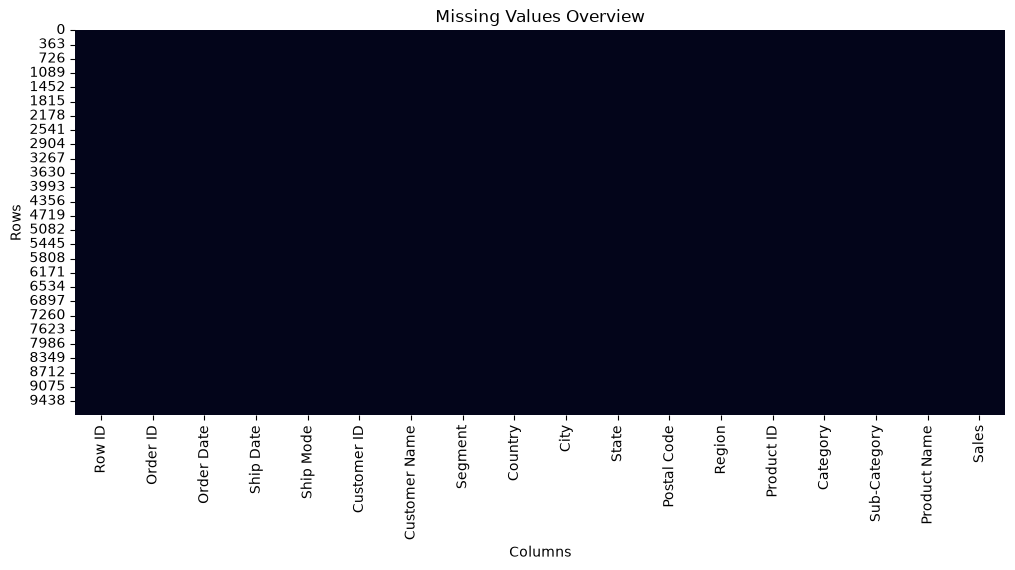

In [22]:
# Visualize the location of missing values in the dataset

plt.figure(figsize=(12, 5))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values Overview")
plt.xlabel("Columns")
plt.ylabel("Rows")

plt.show()

In [23]:
# Missing percentage in each column

missing_percent = df.isnull().mean() * 100

missing_percent = missing_percent.sort_values(ascending=False)

missing_percent

Postal Code      0.112245
Row ID           0.000000
Order ID         0.000000
Order Date       0.000000
Ship Mode        0.000000
Ship Date        0.000000
Customer Name    0.000000
Segment          0.000000
Country          0.000000
Customer ID      0.000000
City             0.000000
State            0.000000
Region           0.000000
Product ID       0.000000
Category         0.000000
Sub-Category     0.000000
Product Name     0.000000
Sales            0.000000
dtype: float64

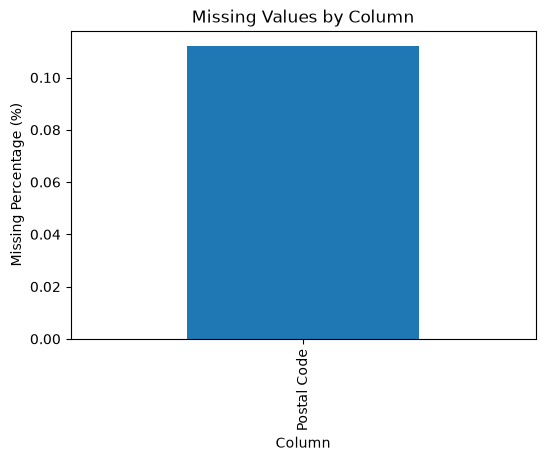

In [24]:
missing_percent[missing_percent > 0].plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Percentage (%)")

plt.show()

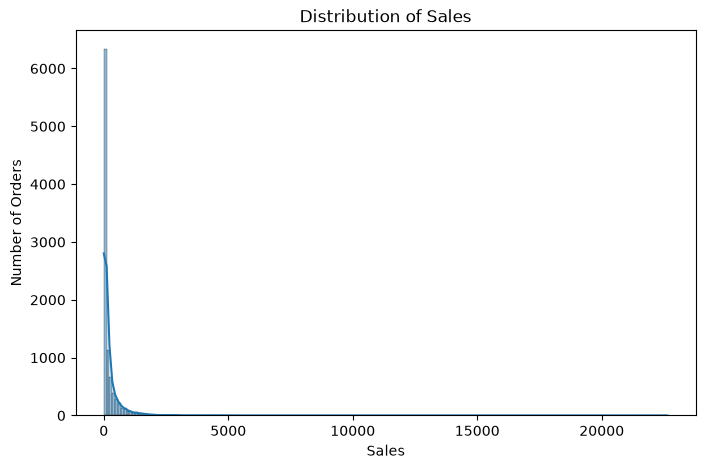

In [25]:
# Distribution of Sales

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Sales", kde=True)

plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Number of Orders")

plt.show()

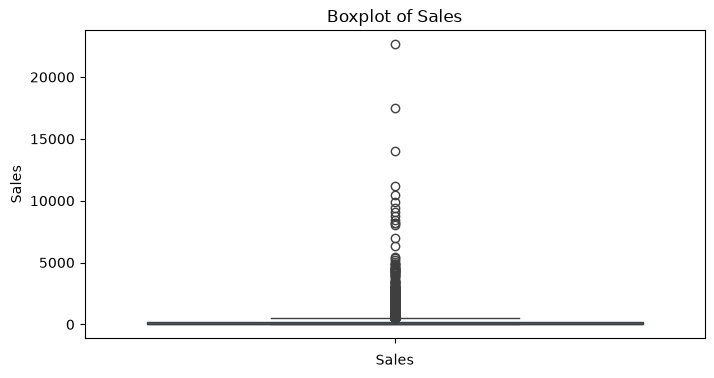

In [28]:
# Boxplot of Sales

plt.figure(figsize=(8, 4))

sns.boxplot(data=df, y="Sales")

plt.title("Boxplot of Sales")
plt.xlabel("Sales")

plt.show()

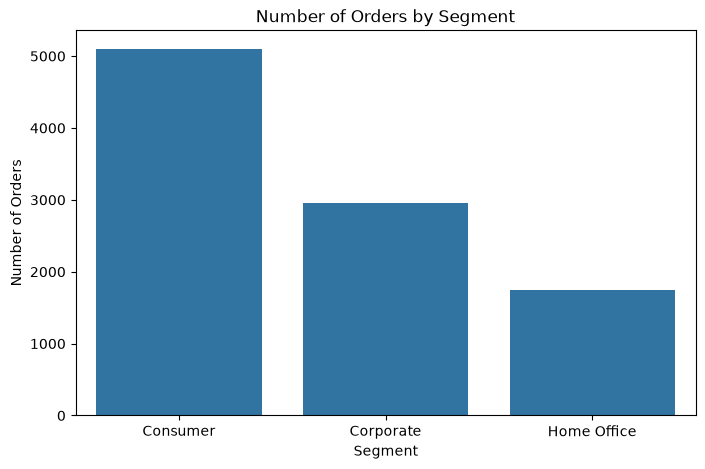

In [29]:
# Count of orders by Segment

plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Segment")

plt.title("Number of Orders by Segment")
plt.xlabel("Segment")
plt.ylabel("Number of Orders")

plt.show()

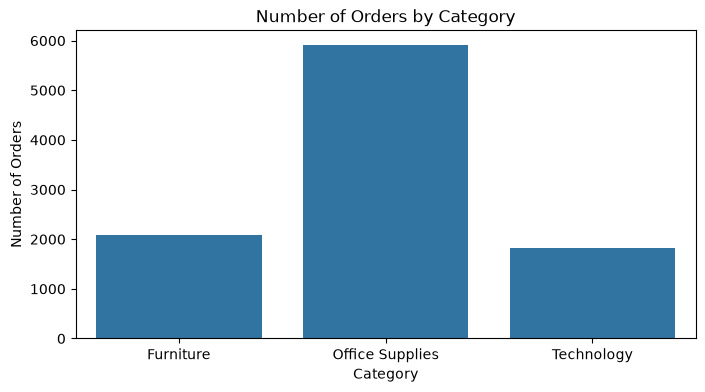

In [30]:
# Count of orders by Category

plt.figure(figsize=(8, 4))

sns.countplot(data=df, x="Category")

plt.title("Number of Orders by Category")
plt.xlabel("Category")
plt.ylabel("Number of Orders")

plt.show()

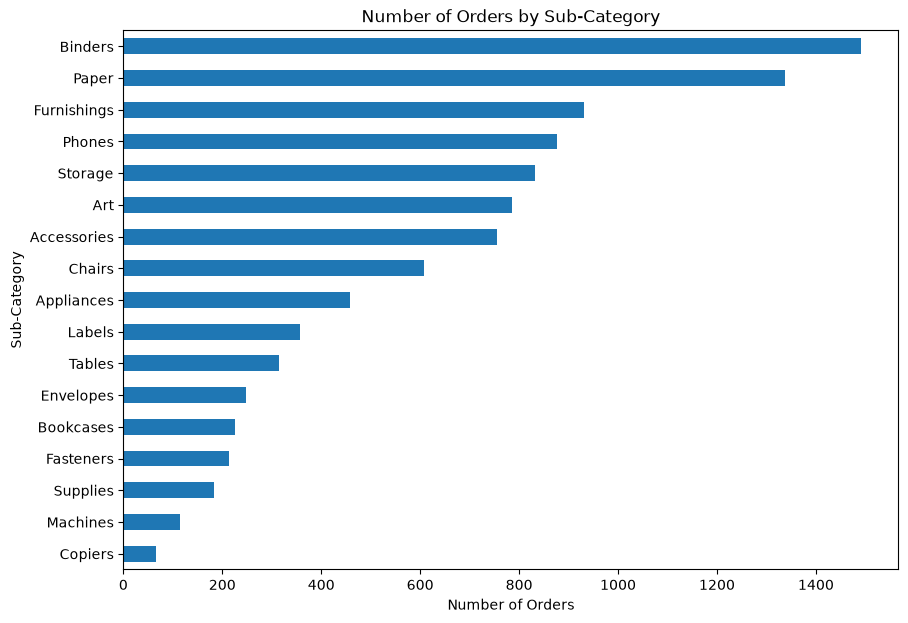

In [31]:
# Number of orders by Sub-Category

sub_category_counts = df["Sub-Category"].value_counts().sort_values()

plt.figure(figsize=(10, 7))

sub_category_counts.plot(kind="barh")

plt.title("Number of Orders by Sub-Category")
plt.xlabel("Number of Orders")
plt.ylabel("Sub-Category")

plt.show()

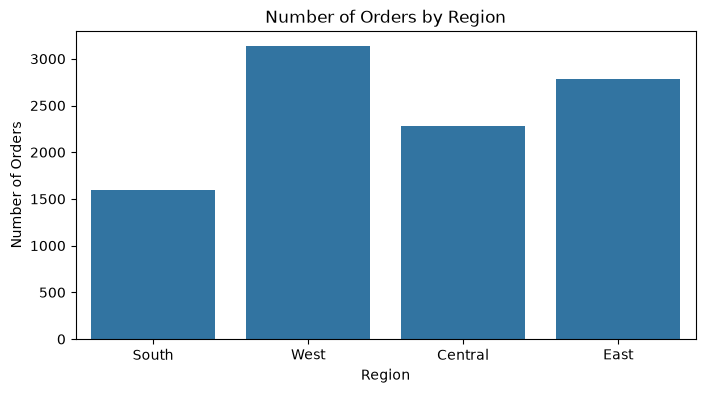

In [32]:
# Number of orders by Region

plt.figure(figsize=(8, 4))

sns.countplot(data=df, x="Region")

plt.title("Number of Orders by Region")
plt.xlabel("Region")
plt.ylabel("Number of Orders")

plt.show()

In [33]:
# Total Sales by Category

category_sales = df.groupby("Category")["Sales"].sum()

category_sales = category_sales.sort_values(ascending=False)

category_sales

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64

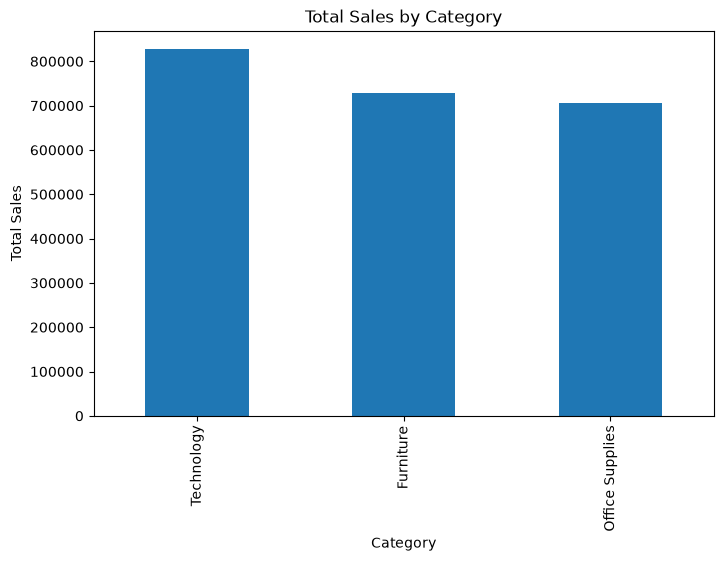

In [34]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.show()

In [35]:
subcat_sales = df.groupby("Sub-Category")["Sales"].sum()

subcat_sales = subcat_sales.sort_values(ascending=False)

subcat_sales

Sub-Category
Phones         327782.4480
Chairs         322822.7310
Storage        219343.3920
Tables         202810.6280
Binders        200028.7850
Machines       189238.6310
Accessories    164186.7000
Copiers        146248.0940
Bookcases      113813.1987
Appliances     104618.4030
Furnishings     89212.0180
Paper           76828.3040
Supplies        46420.3080
Art             26705.4100
Envelopes       16128.0460
Labels          12347.7260
Fasteners        3001.9600
Name: Sales, dtype: float64

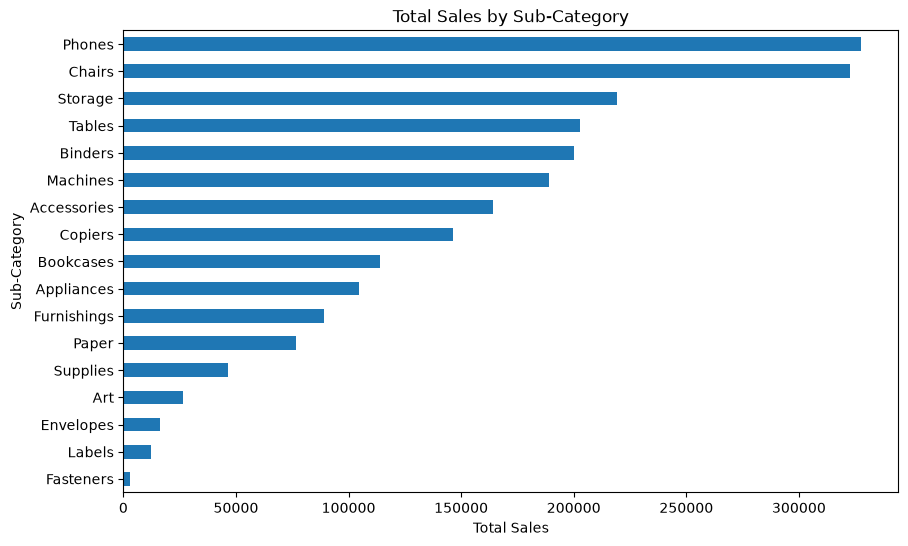

In [38]:
plt.figure(figsize=(10, 6))

subcat_sales.plot(kind="barh")

plt.title("Total Sales by Sub-Category")
plt.xlabel("Total Sales")
plt.ylabel("Sub-Category")


plt.gca().invert_yaxis()
plt.show()

In [39]:
category_region_sales = df.pivot_table(
    values="Sales",
    index="Category",
    columns="Region",
    aggfunc="sum"
)

category_region_sales

Region,Central,East,South,West
Category,,,,
Furniture,160317.4622,206461.388,116531.480,245348.2455
Office Supplies,163590.2430,199940.811,124424.771,217466.5090
Technology,168739.2080,263116.527,148195.208,247404.9300


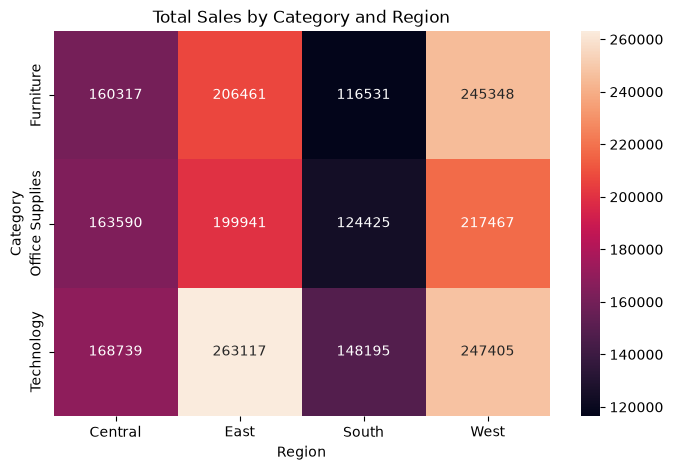

In [40]:
plt.figure(figsize=(8, 5))

sns.heatmap(category_region_sales, annot=True, fmt=".0f")

plt.title("Total Sales by Category and Region")
plt.xlabel("Region")
plt.ylabel("Category")

plt.show()

In [43]:
# Calculate total sales by region
region_sales = df.groupby("Region")["Sales"].sum()

region_sales = region_sales.sort_values(ascending=False)

region_sales

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64

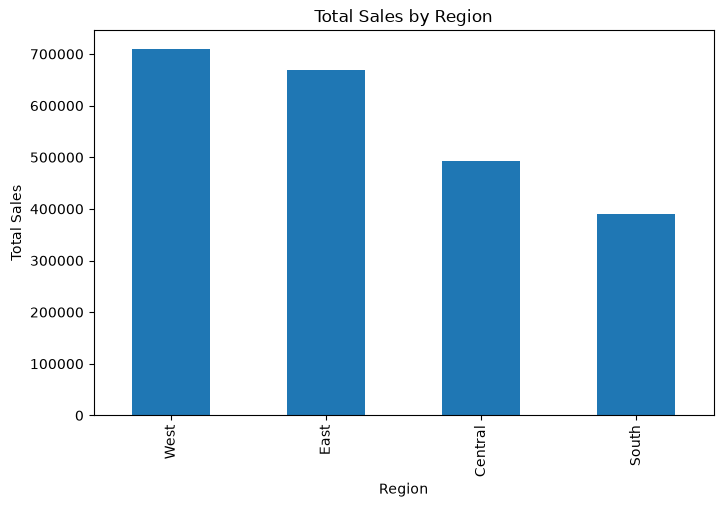

In [44]:
# Visualize total sales by region
plt.figure(figsize=(8, 5))

region_sales.plot(kind="bar")

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.show()

In [46]:
# Convert Order Date to datetime format

df["Order Date"] = pd.to_datetime(df["Order Date"])

In [47]:
# Calculate total sales for each order date

sales_over_time = df.groupby("Order Date")["Sales"].sum()

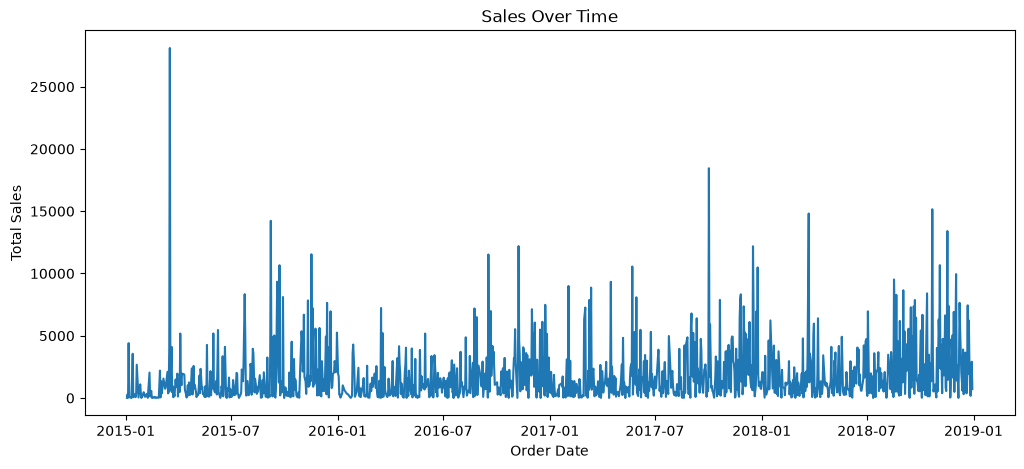

In [48]:
# Plot total sales over time

plt.figure(figsize=(12, 5))

plt.plot(sales_over_time)

plt.title("Sales Over Time")
plt.xlabel("Order Date")
plt.ylabel("Total Sales")

plt.show()

In [49]:
# Extract the month and year from Order Date
df["Month"] = df["Order Date"].dt.to_period("M")

In [50]:
# Calculate total sales for each month
monthly_sales = df.groupby("Month")["Sales"].sum()

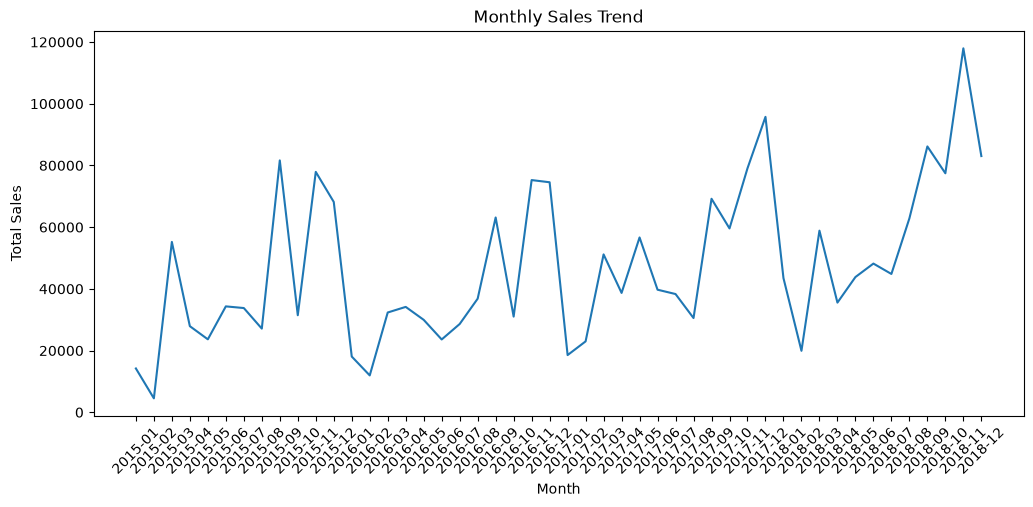

In [52]:
# Convert the month values to strings for plotting
months = monthly_sales.index.astype(str)

# Plot total sales month by month
plt.figure(figsize=(12, 5))
plt.plot(months, monthly_sales)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [53]:
# Extract the year from Order Date
df["Year"] = df["Order Date"].dt.year

In [54]:
# Calculate total sales for each year
yearly_sales = df.groupby("Year")["Sales"].sum()

# Display yearly sales
yearly_sales

Year
2015    479856.2081
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64

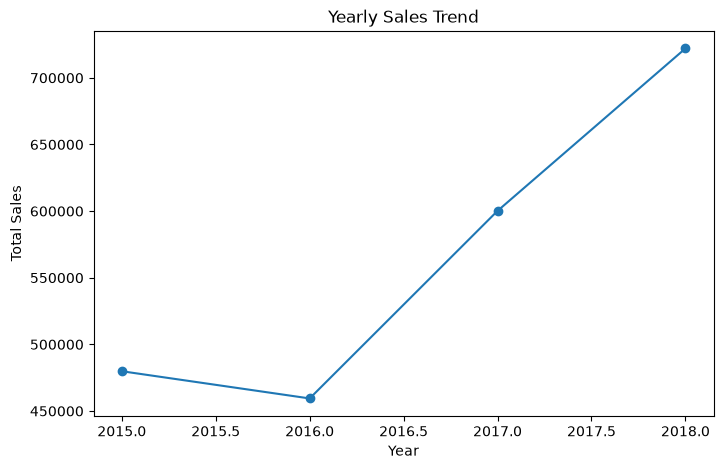

In [55]:
# Plot total sales by year
plt.figure(figsize=(8, 5))
plt.plot(yearly_sales.index, yearly_sales.values, marker="o")
plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.show()

In [56]:
# Extract the month number from Order Date
df["Month_Number"] = df["Order Date"].dt.month

In [57]:
# Calculate total sales for each month of the year
monthly_seasonality = df.groupby("Month_Number")["Sales"].sum()

# Display monthly sales
monthly_seasonality

Month_Number
1      94291.6296
2      59371.1154
3     197573.5872
4     136283.0006
5     154086.7237
6     145837.5233
7     145535.6890
8     157315.9270
9     300103.4117
10    199496.2947
11    350161.7110
12    321480.1695
Name: Sales, dtype: float64

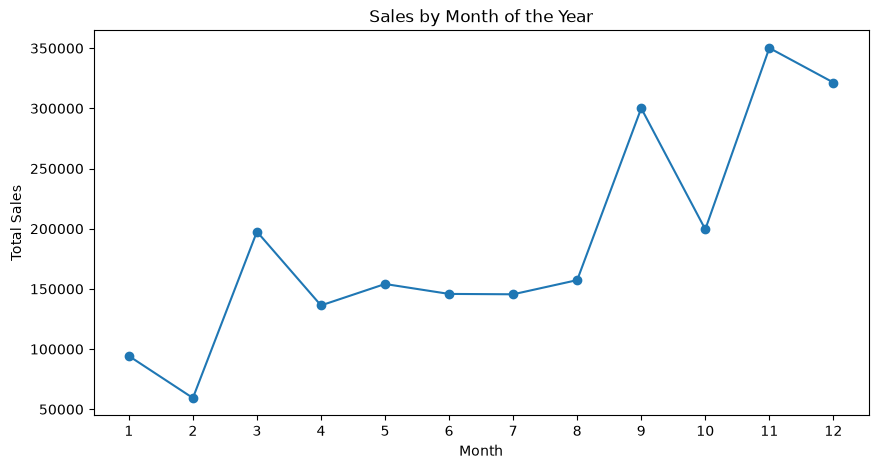

In [58]:
# Plot total sales by month of the year
plt.figure(figsize=(10, 5))
plt.plot(monthly_seasonality.index, monthly_seasonality.values, marker="o")
plt.title("Sales by Month of the Year")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(1, 13))
plt.show()

In [59]:
# Create a pivot table showing sales for each month across each year
year_month_sales = df.pivot_table(
    values="Sales",
    index="Month_Number",
    columns="Year",
    aggfunc="sum"
)

# Display the pivot table
year_month_sales

Year,2015,2016,2017,2018
Month_Number,,,,
1,14205.7070,18066.9576,18542.4910,43476.4740
2,4519.8920,11951.4110,22978.8150,19920.9974
3,55205.7970,32339.3184,51165.0590,58863.4128
4,27906.8550,34154.4685,38679.7670,35541.9101
5,23644.3030,29959.5305,56656.9080,43825.9822
6,34322.9356,23599.3740,39724.4860,48190.7277
7,33781.5430,28608.2590,38320.7830,44825.1040
8,27117.5365,36818.3422,30542.2003,62837.8480
9,81623.5268,63133.6060,69193.3909,86152.8880


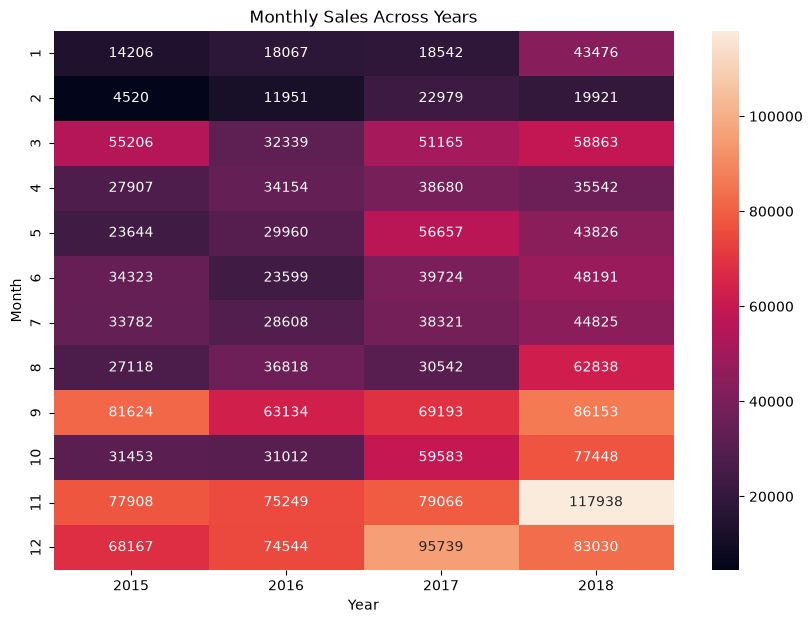

In [60]:
# Visualize monthly sales across different years
plt.figure(figsize=(10, 7))
sns.heatmap(year_month_sales, annot=True, fmt=".0f")
plt.title("Monthly Sales Across Years")
plt.xlabel("Year")
plt.ylabel("Month")
plt.show()

In [61]:
# Find the year-month combination with the highest sales
highest_sales = year_month_sales.stack().idxmax()

# Find the actual highest sales value
highest_value = year_month_sales.stack().max()

print("Highest sales:", highest_value)
print("Year and Month:", highest_sales)

Highest sales: 117938.155
Year and Month: (np.int32(11), np.int32(2018))


In [62]:
# Find the year-month combination with the lowest sales
lowest_sales = year_month_sales.stack().idxmin()

# Find the actual lowest sales value
lowest_value = year_month_sales.stack().min()

print("Lowest sales:", lowest_value)
print("Year and Month:", lowest_sales)

Lowest sales: 4519.892
Year and Month: (np.int32(2), np.int32(2015))


In [65]:
# Calculate year-over-year sales growth
yearly_growth = yearly_sales.pct_change() * 100

# Display the yearly growth percentage
yearly_growth

Year
2015          NaN
2016    -4.255484
2017    30.636812
2018    20.303396
Name: Sales, dtype: float64

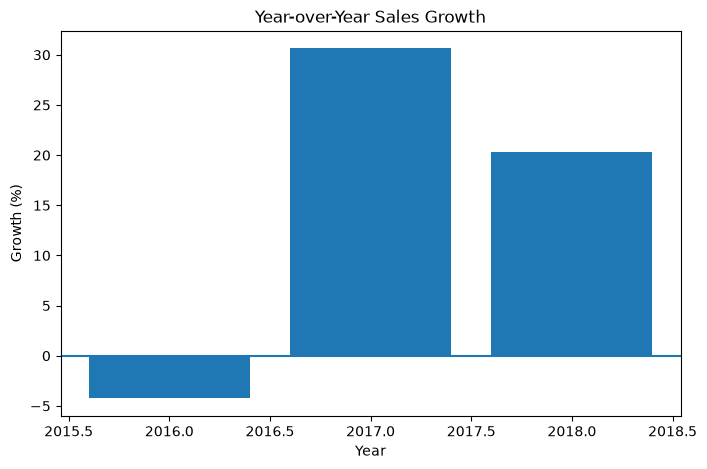

In [66]:
# Plot year-over-year sales growth
plt.figure(figsize=(8, 5))
plt.bar(yearly_growth.index, yearly_growth.values)
plt.title("Year-over-Year Sales Growth")
plt.xlabel("Year")
plt.ylabel("Growth (%)")
plt.axhline(0)
plt.show()

In [ ]:
# pivot table of sales by Category, Region, and Year
category_region_year = df.pivot_table(
    values="Sales",
    index="Category",
    columns=["Region", "Year"],
    aggfunc="sum"
)

# Display the result
category_region_year

Region              Central                                          East  \
Year                   2015        2016       2017        2018       2015   
Category                                                                    
Furniture        32814.3676  35208.5814  49731.992  42562.5212  46833.447   
Office Supplies  36781.1190  25395.8070  45598.263  55815.0540  35656.693   
Technology       33325.0340  41820.7840  50343.625  43249.7650  45162.679   

Region                                                 South              \
Year                  2016       2017       2018        2015        2016   
Category                                                                   
Furniture        53810.052  44964.028  60853.861  26942.7545  23844.6265   
Office Supplies  40078.829  61050.068  63155.221  25785.7980  30228.5850   
Technology       59336.302  72497.442  86120.104  50646.3530  16002.8710   

Region                                        West                          \
Year                   2017        2018       2015        2016        2017   
Category                                                                     
Furniture        27875.8735  37868.2255  49887.312  51190.6075  73241.1465   
Office Supplies  28637.8760  39772.5120  51289.210  37421.1860  47131.3590   
Technology       37022.1540  44523.8300  44731.441  45097.7740  62098.7230   

Region                       
Year                   2018  
Category                     
Furniture        71029.1795  
Office Supplies  81624.7540  
Technology       95476.9920

In [70]:
# Calculate the first and third quartiles of Sales
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate the upper outlier boundary
upper_limit = Q3 + 1.5 * IQR

# Display the upper boundary
upper_limit

np.float64(500.6405000000001)

In [71]:
# Find orders with Sales above the upper outlier boundary
high_sales_orders = df[df["Sales"] > upper_limit]

# Display the number of high-sales orders
high_sales_orders.shape[0]

1145

In [72]:
# Display the main values used to find the outlier boundary
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Upper limit:", upper_limit)

Q1: 17.248
Q3: 210.60500000000002
IQR: 193.35700000000003
Upper limit: 500.6405000000001


In [73]:
# Sort the dataset from highest to lowest Sales
highest_sales_orders = df.sort_values("Sales", ascending=False)

# Display the 10 highest-sales orders
highest_sales_orders[["Order ID", "Product Name", "Category", "Region", "Sales"]].head(10)

,Order ID,Product Name,Category,Region,Sales
2697,CA-2015-145317,Cisco TelePresence System EX90 Videoconferenci...,Technology,South,22638.480
6826,CA-2017-118689,Canon imageCLASS 2200 Advanced Copier,Technology,Central,17499.950
8153,CA-2018-140151,Canon imageCLASS 2200 Advanced Copier,Technology,West,13999.960
2623,CA-2018-127180,Canon imageCLASS 2200 Advanced Copier,Technology,East,11199.968
4190,CA-2018-166709,Canon imageCLASS 2200 Advanced Copier,Technology,East,10499.970
9039,CA-2017-117121,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Central,9892.740
4098,CA-2015-116904,Ibico EPK-21 Electric Binding System,Office Supplies,Central,9449.950
4277,US-2017-107440,"3D Systems Cube Printer, 2nd Generation, Magenta",Technology,East,9099.930
8488,CA-2017-158841,HP Designjet T520 Inkjet Large Format Printer ...,Technology,South,8749.950
6425,CA-2017-143714,Canon imageCLASS 2200 Advanced Copier,Technology,East,8399.976


In [74]:
# Calculate the average Sales value
mean_sales = df["Sales"].mean()

# Display the mean
mean_sales

np.float64(230.76905945918367)

In [75]:
# Calculate the median Sales value
median_sales = df["Sales"].median()

# Display the median
median_sales

np.float64(54.489999999999995)

In [76]:
# Calculate how much Sales values vary around the average
std_sales = df["Sales"].std()

# Display the standard deviation
std_sales

np.float64(626.6518748388042)

In [77]:
# Calculate important Sales percentiles
percentiles = df["Sales"].quantile([0.25, 0.50, 0.75])

# Display the percentiles
percentiles

0.25     17.248
0.50     54.490
0.75    210.605
Name: Sales, dtype: float64

In [78]:
# Check the numerical columns in the dataset
df.select_dtypes(include="number").columns

Index(['Row ID', 'Postal Code', 'Sales', 'Year', 'Month_Number'], dtype='str')